# Regressão — Wine Quality

Parte 1 do trabalho: **prever a nota de qualidade (`quality`) como um valor contínuo**
a partir das variáveis físico-químicas.

O notebook segue as decisões da seção 9 de `exploratory_analisys.ipynb`:

- split treino/teste estratificado pela `quality`;
- vazios preenchidos pela mediana, `type` codificado como 0/1 e padronização,
  tudo ajustado **só no treino**;
- outliers mantidos, testando log nas variáveis de cauda longa e o `RobustScaler`.

Roteiro: baseline → três modelos com a configuração padrão → ajuste de
hiperparâmetros com `GridSearchCV` → avaliação no teste → interpretação.

## 1. Setup

In [1]:
import sys

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns
import pandas as pd
import numpy as np

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import KFold, cross_validate, GridSearchCV
from sklearn.preprocessing import FunctionTransformer, StandardScaler, RobustScaler
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

# Permite importar o módulo src/ a partir da pasta notebooks/
sys.path.append("..")
from src.preparacao import RANDOM_STATE, carregar_dados, dividir_treino_teste, criar_pipeline

# Cores dos gráficos
AZUL = "#2a78d6"
LARANJA = "#eb6834"
CINZA = "#898781"

## 2. Dados e split treino/teste

O dataset limpo é separado em **treino (80%)** e **teste (20%)**. O teste fica guardado
até a seção 7: nenhuma decisão (pré-processamento, escolha de hiperparâmetros) olha
para ele, para que a avaliação final seja feita em vinhos que o modelo nunca viu.

O split é **estratificado pela `quality`**: a proporção de cada nota é a mesma nos
dois conjuntos. Sem isso, as notas raras (3 e 9) poderiam ficar todas de um lado só.

In [2]:
X, y = carregar_dados()
X_train, X_test, y_train, y_test = dividir_treino_teste(X, y)

print(f"Treino: {len(X_train)} vinhos | Teste: {len(X_test)} vinhos")

Treino: 4253 vinhos | Teste: 1064 vinhos


In [3]:
# Proporção de cada nota nos dois conjuntos: deve ser praticamente igual
pd.DataFrame({
    "treino (%)": y_train.value_counts(normalize=True).sort_index() * 100,
    "teste (%)": y_test.value_counts(normalize=True).sort_index() * 100,
    "teste (vinhos)": y_test.value_counts().sort_index(),
}).round(1)

,treino (%),teste (%),teste (vinhos)
quality,,,
3,0.6,0.6,6
4,3.9,3.9,41
5,32.9,33.0,351
6,43.6,43.6,464
7,16.1,16.1,171
8,2.8,2.8,30
9,0.1,0.1,1


## 3. Pré-processamento (pipeline)

O pré-processamento fica num `Pipeline` do scikit-learn (função `criar_pipeline` em
`src/preparacao.py`), que encadeia as etapas num objeto só:

1. **`prep`** trata cada grupo de colunas:
   - `cauda` (`residual sugar`, `chlorides`, `free sulfur dioxide`, `sulphates`):
     mediana nos vazios e, opcionalmente, log;
   - `num` (demais variáveis numéricas): mediana nos vazios;
   - `type`: `red`/`white` vira a coluna `type_white` (0 = tinto, 1 = branco).
2. **`scaler`** padroniza todas as colunas.
3. **`model`** é o modelo de regressão.

**Por que um pipeline?** Ao chamar `.fit()`, cada etapa aprende (a mediana, a média, o
desvio padrão) **só com os dados recebidos**. Na validação cruzada isso é essencial:
em cada rodada, o fold de validação faz o papel de "teste" e não pode influenciar a
mediana nem a padronização. Com o pipeline, tudo é recalculado em cada rodada
automaticamente, sem vazamento de dados.

In [4]:
# Exemplo: o pipeline com o Ridge (o Jupyter mostra o diagrama das etapas)
criar_pipeline(Ridge())

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cauda', ...), ('num', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature

## 4. Validação cruzada e métricas

Para comparar modelos sem tocar no teste, usamos **validação cruzada com 5 folds**: o
treino é dividido em 5 partes; o modelo treina em 4 e é avaliado na 5ª, num rodízio.
A nota de cada modelo é a média das 5 rodadas.

Métricas (todas comparam a nota prevista com a real):

- **RMSE**: erro típico em pontos de nota, pesando mais os erros grandes.
  É a **métrica principal**, usada para escolher os hiperparâmetros, porque os erros
  grandes acontecem justamente nas notas raras (3, 4, 8 e 9).
- **MAE**: erro médio em pontos de nota; o mais fácil de interpretar.
- **R²**: fração da variação das notas explicada pelo modelo
  (0 = igual a chutar a média; 1 = acerta tudo).

In [5]:
# 5 folds embaralhados, sempre os mesmos para todos os modelos
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# O sklearn trata toda métrica como "maior é melhor", por isso os erros vêm negativos
METRICAS = {
    "RMSE": "neg_root_mean_squared_error",
    "MAE": "neg_mean_absolute_error",
    "R2": "r2",
}


def avaliar_cv(pipeline):
    """Roda a validação cruzada no treino e devolve a média de cada métrica."""
    resultado = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=METRICAS)

    # "test_" aqui é o fold de validação de cada rodada, não o conjunto de teste
    return {
        "RMSE": -resultado["test_RMSE"].mean(),
        "MAE": -resultado["test_MAE"].mean(),
        "R2": resultado["test_R2"].mean(),
    }

## 5. Baseline e modelos com a configuração padrão

O **baseline** (`DummyRegressor`) chuta sempre a nota média do treino. Ele não aprende
nada e serve de régua: um modelo só é útil se errar menos que ele.

Os três modelos (escolhidos na discussão do projeto):

- **Ridge**: regressão linear com penalidade nos coeficientes; lida com a
  multicolinearidade encontrada na EDA e permite interpretar os coeficientes.
- **Random Forest**: média de centenas de árvores treinadas em partes diferentes dos
  dados.
- **Gradient Boosting** (`HistGradientBoostingRegressor`): árvores em sequência, cada
  uma corrigindo os erros das anteriores.

Os modelos de árvore capturam relações não lineares e a interação entre `type` e as
demais variáveis, que a EDA mostrou ser importante.

In [6]:
modelos_padrao = {
    "Baseline (média)": DummyRegressor(strategy="mean"),
    "Ridge": Ridge(),
    "Random Forest": RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingRegressor(random_state=RANDOM_STATE),
}

resultados_padrao = pd.DataFrame(
    {nome: avaliar_cv(criar_pipeline(modelo)) for nome, modelo in modelos_padrao.items()}
).T

resultados_padrao.round(3)

,RMSE,MAE,R2
Baseline (média),0.880,0.695,-0.001
Ridge,0.735,0.567,0.301
Random Forest,0.696,0.537,0.373
Gradient Boosting,0.702,0.544,0.362


**Observações:**

- Todos os modelos erram bem menos que o baseline: o RMSE cai de 0,88 para 0,70–0,74.
- O R² fica entre 0,30 (Ridge) e 0,37 (Random Forest): os modelos explicam cerca de
  um terço da variação das notas. É modesto, como a EDA previa: nenhuma variável tem
  correlação forte com a `quality`.
- Os modelos de árvore saem na frente já sem ajuste, por capturarem relações não
  lineares que o Ridge não enxerga.

## 6. Ajuste de hiperparâmetros (GridSearchCV)

O `GridSearchCV` testa **todas as combinações** de uma lista de hiperparâmetros. Cada
combinação é avaliada com a mesma validação cruzada da seção 4, e a melhor (menor
RMSE) é treinada de novo no treino inteiro.

In [7]:
def ajustar(modelo, grade):
    """Roda o GridSearchCV no pipeline do modelo e escolhe a combinação de menor RMSE."""
    busca = GridSearchCV(
        criar_pipeline(modelo), grade, cv=cv, scoring=METRICAS,
        refit="RMSE",   # métrica usada para escolher a melhor combinação
        n_jobs=-1,      # usa todos os núcleos do processador
    )
    busca.fit(X_train, y_train)
    return busca


def resumo(busca):
    """Métricas de validação cruzada da melhor combinação encontrada."""
    i = busca.best_index_
    r = busca.cv_results_
    return {
        "RMSE": -r["mean_test_RMSE"][i],
        "MAE": -r["mean_test_MAE"][i],
        "R2": r["mean_test_R2"][i],
    }

### 6.1 Ridge

- **`alpha`**: força da penalidade nos coeficientes. Perto de 0, vira a regressão
  linear comum; muito alto, os coeficientes vão a zero e o modelo vira o baseline.
- **`scaler`**: `StandardScaler` (média e desvio padrão) ou `RobustScaler` (mediana e
  intervalo interquartil, menos afetado pelos outliers).
- **`prep__cauda__log`**: com ou sem log nas variáveis de cauda longa.

Padronização e log só são testados no Ridge: as árvores fazem perguntas do tipo
"valor > X?", cuja resposta não muda com a escala.

In [8]:
# feature_names_out="one-to-one": o log mantém os nomes das colunas (usado na seção 8)
LOG = FunctionTransformer(np.log1p, feature_names_out="one-to-one")

grade_ridge = {
    "model__alpha": [0.01, 0.1, 1, 10, 100, 1000],
    "scaler": [StandardScaler(), RobustScaler()],
    "prep__cauda__log": ["passthrough", LOG],
}

busca_ridge = ajustar(Ridge(), grade_ridge)
busca_ridge.best_params_

{'model__alpha': 100,
 'prep__cauda__log': FunctionTransformer(feature_names_out='one-to-one', func=<ufunc 'log1p'>),
 'scaler': StandardScaler()}

In [9]:
# Todas as 24 combinações, da melhor para a pior
tabela_ridge = pd.DataFrame({
    "alpha": busca_ridge.cv_results_["param_model__alpha"],
    "scaler": [type(s).__name__ for s in busca_ridge.cv_results_["param_scaler"]],
    "log": ["sem log" if l == "passthrough" else "com log"
            for l in busca_ridge.cv_results_["param_prep__cauda__log"]],
    "RMSE": -busca_ridge.cv_results_["mean_test_RMSE"],
})

tabela_ridge.sort_values("RMSE").round(4)

,alpha,scaler,log,RMSE
18,100.00,StandardScaler,com log,0.7270
19,100.00,RobustScaler,com log,0.7272
15,10.00,RobustScaler,com log,0.7276
14,10.00,StandardScaler,com log,0.7280
11,1.00,RobustScaler,com log,0.7282
10,1.00,StandardScaler,com log,0.7282
7,0.10,RobustScaler,com log,0.7283
6,0.10,StandardScaler,com log,0.7283
3,0.01,RobustScaler,com log,0.7283
2,0.01,StandardScaler,com log,0.7283


**Observações:**

- **O log foi o que mais fez diferença.** Todas as combinações com log ficam à
  frente das sem log (RMSE ≈ 0,728 contra ≈ 0,735). Isso confirma a EDA: nas
  variáveis de cauda longa, a relação com a nota fica mais próxima de uma reta
  depois do log.
- **O tipo de padronização quase não importa** (diferença na 4ª casa decimal): os
  outliers não chegaram a prejudicar o `StandardScaler`.
- **O `alpha` quase não muda nada entre 0,01 e 100** e só piora em 1000, quando a
  penalidade fica forte demais e "encolhe" os coeficientes em direção ao baseline.
  Com 4.253 vinhos e só 12 variáveis, há dados suficientes para os coeficientes
  ficarem estáveis mesmo com pouca penalidade.

### 6.2 Random Forest

- **`n_estimators`**: número de árvores. Mais árvores deixam a média mais estável.
- **`max_depth`**: profundidade máxima de cada árvore (`None` = sem limite).
- **`min_samples_leaf`**: mínimo de vinhos em cada folha. Valores maiores impedem a
  árvore de decorar casos isolados.

In [10]:
grade_rf = {
    "model__n_estimators": [200, 500],
    "model__max_depth": [10, 20, None],
    "model__min_samples_leaf": [1, 3, 5],
}

busca_rf = ajustar(RandomForestRegressor(random_state=RANDOM_STATE), grade_rf)
busca_rf.best_params_

{'model__max_depth': None,
 'model__min_samples_leaf': 1,
 'model__n_estimators': 500}

### 6.3 Gradient Boosting

- **`learning_rate`**: quanto cada árvore nova corrige as anteriores. Menor = aprende
  mais devagar, com mais cuidado.
- **`max_iter`**: número de árvores em sequência.
- **`max_depth`**: profundidade de cada árvore (`None` = sem limite, controlada pelo
  número máximo de folhas).

In [11]:
grade_gb = {
    "model__learning_rate": [0.01, 0.03, 0.1],
    "model__max_iter": [100, 200, 500],
    "model__max_depth": [3, 6, None],
}

busca_gb = ajustar(HistGradientBoostingRegressor(random_state=RANDOM_STATE), grade_gb)
busca_gb.best_params_

{'model__learning_rate': 0.03,
 'model__max_depth': None,
 'model__max_iter': 200}

### 6.4 Antes × depois do ajuste

Comparação na validação cruzada (ainda sem usar o teste): quanto o ajuste melhorou
cada modelo?

In [12]:
buscas = {"Ridge": busca_ridge, "Random Forest": busca_rf, "Gradient Boosting": busca_gb}

comparacao = pd.DataFrame({
    "RMSE padrão": resultados_padrao.loc[list(buscas), "RMSE"],
    "RMSE ajustado": [resumo(b)["RMSE"] for b in buscas.values()],
})
comparacao["melhora"] = comparacao["RMSE padrão"] - comparacao["RMSE ajustado"]

comparacao.round(4)

,RMSE padrão,RMSE ajustado,melhora
Ridge,0.7347,0.7270,0.0077
Random Forest,0.6959,0.6918,0.0041
Gradient Boosting,0.7022,0.6973,0.0049


**Observações:**

- **O ajuste melhorou pouco os três modelos** (no máximo 0,008 de RMSE). As
  configurações padrão do scikit-learn já funcionam bem para um dataset deste
  tamanho; o limite está nos dados (correlações fracas e notas subjetivas dos
  degustadores), não na configuração dos modelos.
- No Random Forest, a melhor combinação é praticamente o padrão com mais árvores:
  sem limite de profundidade e folhas com 1 vinho.
- No Gradient Boosting, a melhor combinação (`learning_rate` = 0,03 e 200 árvores)
  ficou no meio da grade: os valores vizinhos foram testados e são piores, então não
  há sinal de que um valor fora da lista seria melhor.
- A ordem se mantém: Random Forest, Gradient Boosting e Ridge.

## 7. Avaliação no conjunto de teste

Agora, e só agora, os modelos ajustados são avaliados nos vinhos do teste. É a
estimativa de como eles se sairiam com vinhos novos.

In [13]:
modelos_finais = {
    "Baseline (média)": criar_pipeline(DummyRegressor(strategy="mean")).fit(X_train, y_train),
    "Ridge": busca_ridge.best_estimator_,
    "Random Forest": busca_rf.best_estimator_,
    "Gradient Boosting": busca_gb.best_estimator_,
}

previsoes = {nome: modelo.predict(X_test) for nome, modelo in modelos_finais.items()}

resultados_teste = pd.DataFrame({
    nome: {
        "RMSE": root_mean_squared_error(y_test, y_pred),
        "MAE": mean_absolute_error(y_test, y_pred),
        "R2": r2_score(y_test, y_pred),
    }
    for nome, y_pred in previsoes.items()
}).T

resultados_teste.round(3)

,RMSE,MAE,R2
Baseline (média),0.880,0.695,-0.000
Ridge,0.721,0.557,0.329
Random Forest,0.679,0.521,0.406
Gradient Boosting,0.684,0.527,0.397


**Observações:**

- **O Random Forest foi o melhor modelo**: RMSE de 0,68, MAE de 0,52 e R² de 0,41.
  Em média, ele erra a nota em cerca de meio ponto.
- O Gradient Boosting ficou muito perto (RMSE de 0,684). A diferença de 0,005 é
  pequena demais para afirmar que um é melhor que o outro: na prática, empatam.
  O Ridge fica claramente atrás (RMSE de 0,72).
- Os resultados no teste são parecidos com os da validação cruzada (RMSE de 0,69 do
  Random Forest na validação). Isso indica que a estimativa é confiável: a escolha
  dos hiperparâmetros não "decorou" o treino.

### 7.1 Onde os modelos erram

Para cada nota real, a distribuição das notas previstas. A linha tracejada marca a
previsão perfeita (prevista = real).

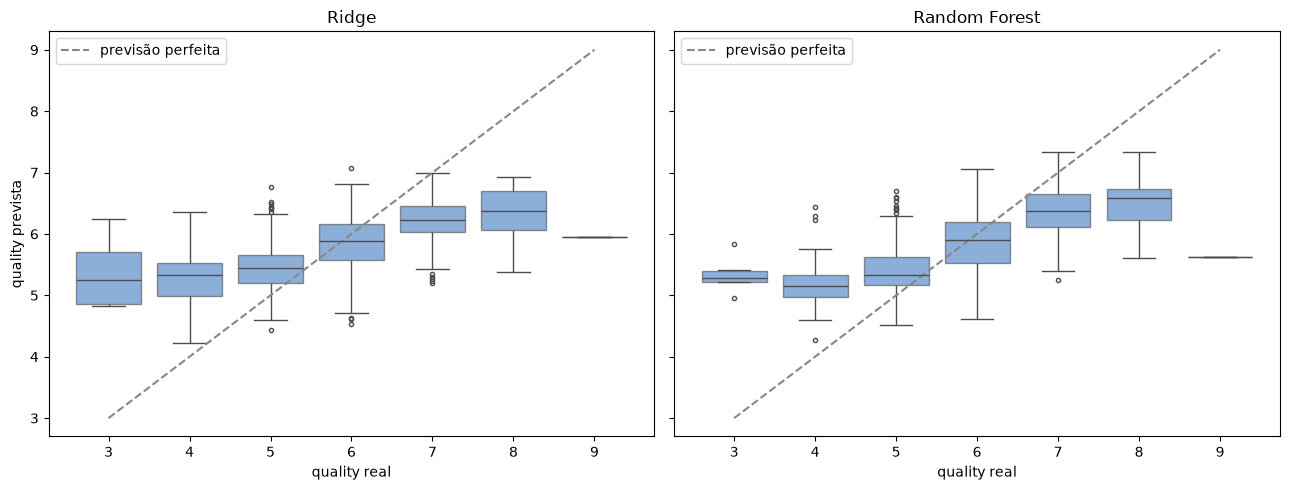

In [14]:
# Modelo de árvore escolhido pela validação cruzada (não pelo teste)
melhor_arvore = min(["Random Forest", "Gradient Boosting"], key=lambda n: resumo(buscas[n])["RMSE"])
notas = sorted(y_test.unique())

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

for ax, nome in zip(axes, ["Ridge", melhor_arvore]):
    sns.boxplot(x=y_test, y=previsoes[nome], order=notas, color=AZUL, ax=ax,
                boxprops={"alpha": 0.6}, flierprops={"markersize": 3})
    # As caixas ficam nas posições 0, 1, 2...; a linha liga cada posição à nota real
    ax.plot(range(len(notas)), notas, "--", color=CINZA, label="previsão perfeita")
    ax.set_title(nome)
    ax.set_xlabel("quality real")
    ax.set_ylabel("quality prevista")
    ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

In [15]:
# Erro médio (MAE) por nota real, no teste
erro_por_nota = pd.DataFrame({
    nome: (y_test - y_pred).abs().groupby(y_test).mean()
    for nome, y_pred in previsoes.items()
})
erro_por_nota["vinhos no teste"] = y_test.value_counts().sort_index()

erro_por_nota.round(2)

,Baseline (média),Ridge,Random Forest,Gradient Boosting,vinhos no teste
quality,,,,,
3,2.8,2.36,2.33,2.24,6
4,1.8,1.28,1.21,1.16,41
5,0.8,0.48,0.44,0.42,351
6,0.2,0.36,0.39,0.41,464
7,1.2,0.79,0.63,0.65,171
8,2.2,1.66,1.49,1.54,30
9,3.2,3.05,3.37,3.41,1


**Observações:**

- **Os modelos "puxam" as previsões para o centro.** As caixas são bem mais achatadas
  que a linha da previsão perfeita: vinhos de nota 3 recebem previsões perto de 5,3;
  vinhos de nota 8, perto de 6,5.
- O erro médio é de cerca de 0,4 ponto nas notas 5 e 6, mas sobe para 1,5 na nota 8
  e mais de 2 na nota 3 (a nota 9 tem um único vinho no teste, então o valor dela
  não é representativo).
- Na nota 6 o baseline erra menos que os modelos, porque ele sempre chuta ≈ 5,8,
  perto da nota mais comum. Os modelos trocam um pouco de acerto no centro por
  acerto nas pontas.
- **Causa:** há poucos exemplos extremos para aprender (no treino, 24 vinhos com nota
  3 e 4 com nota 9). Chutar perto do centro é o que minimiza o erro na maioria dos
  vinhos. Essa limitação motiva a Parte 2, em que as notas são agrupadas em faixas e
  as classes raras recebem tratamento próprio.

## 8. Interpretação: quais variáveis impactam mais

### 8.1 Coeficientes do Ridge

Como todas as variáveis foram padronizadas, os coeficientes estão na mesma escala:
cada um indica **quanto a nota prevista muda quando a variável aumenta um desvio
padrão**, mantendo as outras fixas. O sinal diz a direção (positivo = nota maior).

Cuidado com pares multicolineares (`alcohol` × `density`, `residual sugar` ×
`density`): o modelo divide o "crédito" entre eles, então o coeficiente de cada um
isoladamente pode enganar.

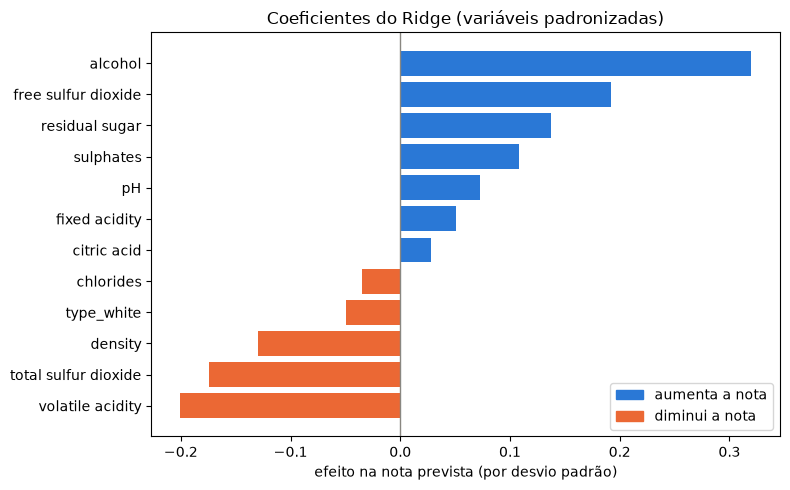

alcohol                 0.320
volatile acidity       -0.201
free sulfur dioxide     0.192
total sulfur dioxide   -0.175
residual sugar          0.138
density                -0.129
sulphates               0.109
pH                      0.073
fixed acidity           0.050
type_white             -0.050
chlorides              -0.035
citric acid             0.028
dtype: float64

In [16]:
ridge_final = busca_ridge.best_estimator_

# Nomes das colunas na saída do pré-processamento e coeficientes do modelo
coeficientes = pd.Series(
    ridge_final["model"].coef_,
    index=ridge_final[:-1].get_feature_names_out(),
).sort_values()

cores = [AZUL if c > 0 else LARANJA for c in coeficientes]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(coeficientes.index, coeficientes, color=cores)
ax.axvline(0, color=CINZA, linewidth=1)
ax.set_title("Coeficientes do Ridge (variáveis padronizadas)")
ax.set_xlabel("efeito na nota prevista (por desvio padrão)")

# Legenda das cores: o sinal do coeficiente
ax.legend(handles=[Patch(color=AZUL, label="aumenta a nota"),
                   Patch(color=LARANJA, label="diminui a nota")], loc="lower right")

plt.tight_layout()
plt.show()

coeficientes.sort_values(key=abs, ascending=False).round(3)

**Observações** (nas variáveis com log, o coeficiente se refere ao log da variável):

- **`alcohol` tem o maior efeito** (+0,32): mais álcool, nota maior.
- **`volatile acidity` é a que mais reduz a nota** (−0,20). A acidez volátil
  dá ao vinho o gosto de vinagre.
- **`free sulfur dioxide` (+0,19) e `total sulfur dioxide` (−0,17) têm sinais
  opostos.** A leitura conjunta faz sentido químico: o SO₂ livre protege o vinho, e
  o total alto indica excesso de conservante. Reforça essa leitura o fato de que,
  sozinho, o SO₂ livre quase não se correlaciona com a nota (≈ 0,05): ele só ganha
  peso em conjunto com o total. Mas o par é correlacionado, então os valores
  individuais devem ser lidos com cautela.
- **`residual sugar` (+0,14) e `density` (−0,13) pedem o mesmo cuidado.** A densidade
  é praticamente determinada pelo álcool e pelo açúcar, e o modelo usa as três
  juntas. Na EDA o açúcar quase não tinha relação direta com a nota; o coeficiente
  positivo aqui aparece porque ele é "descontado" da densidade.
- `type_white` tem efeito pequeno (−0,05).

### 8.2 Permutation importance

Os modelos de árvore não têm coeficientes. A **permutation importance** mede a
importância de outra forma: embaralha uma coluna no conjunto de teste (quebrando a
relação dela com a nota) e mede quanto o RMSE piora. Quanto maior a piora, mais o
modelo depende daquela variável.

O mesmo método é aplicado ao Ridge, para comparar os dois modelos na mesma régua.

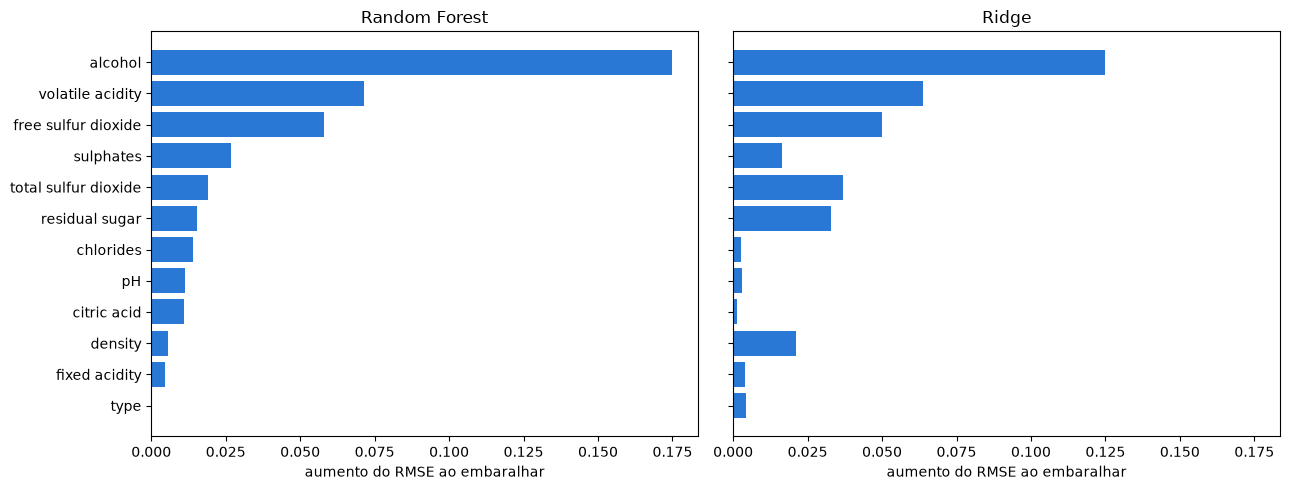

,Random Forest,Ridge
alcohol,0.1749,0.1247
volatile acidity,0.0715,0.0639
free sulfur dioxide,0.0580,0.0500
sulphates,0.0267,0.0164
total sulfur dioxide,0.0191,0.0368
residual sugar,0.0154,0.0330
chlorides,0.0141,0.0026
pH,0.0115,0.0028
citric acid,0.0111,0.0014
density,0.0057,0.0212


In [17]:
def importancia(modelo):
    """Aumento médio do RMSE no teste ao embaralhar cada coluna (10 repetições)."""
    resultado = permutation_importance(
        modelo, X_test, y_test, scoring="neg_root_mean_squared_error",
        n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1,
    )
    return pd.Series(resultado.importances_mean, index=X_test.columns)


importancias = pd.DataFrame({
    melhor_arvore: importancia(modelos_finais[melhor_arvore]),
    "Ridge": importancia(ridge_final),
}).sort_values(melhor_arvore)

# Mesma escala nos dois eixos, para comparar os modelos
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True, sharex=True)

for ax, nome in zip(axes, importancias.columns):
    ax.barh(importancias.index, importancias[nome], color=AZUL)
    ax.set_title(nome)
    ax.set_xlabel("aumento do RMSE ao embaralhar")

plt.tight_layout()
plt.show()

importancias.sort_values(melhor_arvore, ascending=False).round(4)

**Observações:**

- **Os dois modelos concordam nas três variáveis mais importantes**: `alcohol`
  (de longe), `volatile acidity` e `free sulfur dioxide`. É o mesmo resultado dos
  coeficientes do Ridge e da EDA.
- O Ridge depende mais de `density`, `residual sugar` e `total sulfur dioxide` do
  que o Random Forest: o modelo linear usa essas variáveis em combinação para
  compensar os pares correlacionados. As árvores obtêm a mesma informação de outra
  forma.
- **`type` tem importância quase zero nos dois modelos**, o que parece contrariar a
  EDA. A explicação provável é que tintos e brancos diferem tanto na química
  (`total sulfur dioxide`, `chlorides` etc.) que o modelo já "sabe" o tipo pelas
  outras colunas. Embaralhar só a coluna `type` não remove essa informação. Ou seja,
  o comportamento diferente por tipo continua existindo, mas a coluna `type` é
  redundante. Essa é uma limitação conhecida da permutation importance: ela
  subestima variáveis cuja informação aparece também em outras colunas.

## 9. Conclusões

1. **O Random Forest foi o melhor modelo**, com RMSE de 0,68, MAE de 0,52 e R² de
   0,41 no teste: erra a nota em cerca de meio ponto e explica cerca de 41% da
   variação. O Gradient Boosting empatou na prática; o Ridge ficou atrás
   (RMSE de 0,72).

2. **Os modelos de árvore superam o linear** porque capturam relações não lineares
   entre as variáveis e a nota. O Ridge continua útil pela interpretação dos
   coeficientes.

3. **O ajuste de hiperparâmetros trouxe pouco ganho** (menos de 0,01 de RMSE). O
   maior ganho do Ridge veio de uma decisão de pré-processamento (o log nas
   variáveis de cauda longa), não do `alpha`. O limite de desempenho está nos
   dados: as correlações são fracas e a nota é uma avaliação subjetiva.

4. **As variáveis que mais impactam a nota são `alcohol`, `volatile acidity` e
   `free sulfur dioxide`**, de forma consistente nos coeficientes do Ridge, na
   permutation importance dos dois modelos e na EDA. O `alcohol` aumenta a nota; a
   `volatile acidity` diminui.

5. **Limitação principal: os modelos erram muito nas notas extremas.** Com poucos
   exemplos de vinhos muito ruins ou muito bons, as previsões ficam presas entre
   5 e 7. Para identificar esses vinhos, a regressão não basta, e essa é a
   motivação da Parte 2 (classificação em faixas de qualidade).